## 🔧 Cell 1 · Setup

Imports the libraries, defines file/folder paths (creating the output folders if missing), and sets the device lists.

- `BIG_DEVICES` → all major appliances
- `HABIT_DEVICES` → appliances whose usage habits we study

In [34]:
import os
os.environ["OMP_NUM_THREADS"] = "2"

import warnings
warnings.filterwarnings("ignore", category=UserWarning, module="sklearn.cluster._kmeans")

from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.cluster import KMeans
from sklearn.ensemble import IsolationForest
from sklearn.metrics import silhouette_score

REPO = Path.cwd().parent if Path.cwd().name == "energy" else Path.cwd()
OUT = REPO / "energy"
CLEAN_DIR = REPO / "data_clean"
OUT.mkdir(exist_ok=True)
CLEAN_DIR.mkdir(exist_ok=True)

CLEAN_CSV = OUT / "clean_energy.csv"        # Task 1 output: used for fault detection
HABITS_FILE = (REPO / "Augmented Smart Home with Weather Information"
               / "Augmented Smart Home with Weather Information" / "HomeC_augmented.csv")
assert CLEAN_CSV.exists(), f"{CLEAN_CSV} not found: run 01_clean_explore.ipynb first"
assert HABITS_FILE.exists(), f"habits dataset not found: {HABITS_FILE}"

BIG_DEVICES = ["Air conditioning [kW]", "Water heater [kW]", "Car charger [kW]",
               "Pool Pump [kW]", "Outdoor lights [kW]", "Home Theater [kW]", "Laundry [kW]"]
HABIT_DEVICES = ["Water heater [kW]", "Pool Pump [kW]", "Laundry [kW]",
                 "Home Theater [kW]", "Car charger [kW]"]

## 🧹 Cell 2 · Load & Clean Smart-Home Data

Reads the HomeC file, fixes the time column, and converts the data to **hourly averages**.

- Adds `hour`, `weekday`, and `is_weekend` columns
- Prints per-device stats (mean, max, % of hours in use)
- 💾 Saves the result as `task3_habits.csv`

In [35]:
df = pd.read_csv(HABITS_FILE, low_memory=False,
                 usecols=["time", "use_HO", "temperature"] + BIG_DEVICES)


t_text = pd.to_datetime(df["time"], errors="coerce")
if t_text.notna().mean() > 0.9:
    df["time"] = t_text
else:
    df["time"] = pd.to_datetime(pd.to_numeric(df["time"], errors="coerce"), unit="s")

df = df.dropna(subset=["time"]).set_index("time").sort_index()
assert len(df) > 0, "no valid time values found in the data"

df = df.apply(pd.to_numeric, errors="coerce").resample("1h").mean()


df["hour"] = df.index.hour
df["weekday"] = df.index.day_of_week
df["is_weekend"] = (df["weekday"] >= 5).astype(int)

print(df.shape, df.index.min(), df.index.max())
print("nulls:", int(df.isna().sum().sum()))

THRESH = 0.05
stats = pd.DataFrame({
    "mean_kW": df[BIG_DEVICES].mean(),
    "max_kW": df[BIG_DEVICES].max(),
    "pct_hours_above_0.05kW": (df[BIG_DEVICES] > THRESH).mean() * 100,
})
print(stats.round(3))

df.to_csv(CLEAN_DIR / "task3_habits.csv")
print("saved:", CLEAN_DIR / "task3_habits.csv")

(8399, 12) 2016-01-01 05:00:00 2016-12-16 03:00:00
nulls: 0
                       mean_kW  max_kW  pct_hours_above_0.05kW
Air conditioning [kW]    0.023   0.049                   0.000
Water heater [kW]        0.069   0.140                  63.805
Car charger [kW]         1.995   2.594                 100.000
Pool Pump [kW]           0.147   0.240                  99.988
Outdoor lights [kW]      0.126   0.139                  99.976
Home Theater [kW]        0.021   0.040                   0.000
Laundry [kW]             0.039   0.096                  18.121
saved: d:\Hass\data_clean\task3_habits.csv


## 📊 Cell 3 · Explore Device Patterns

- Prints summary statistics for each device
- Measures how much each device's usage **swings during the day**
- Plots 24-hour usage curves (weekday vs weekend)
- 💾 Saves the plot as `device_daily_profiles.png`

                        count   mean    std    min     5%    25%    50%  \
Air conditioning [kW]  8399.0  0.023  0.011  0.005  0.006  0.014  0.023   
Water heater [kW]      8399.0  0.069  0.031  0.024  0.039  0.047  0.054   
Car charger [kW]       8399.0  1.995  0.397  0.232  1.413  1.584  2.043   
Pool Pump [kW]         8399.0  0.147  0.040  0.025  0.100  0.114  0.132   
Outdoor lights [kW]    8399.0  0.126  0.004  0.012  0.120  0.123  0.126   
Home Theater [kW]      8399.0  0.021  0.007  0.004  0.013  0.015  0.018   
Laundry [kW]           8399.0  0.039  0.013  0.010  0.023  0.030  0.036   

                         75%    95%    max  unique  
Air conditioning [kW]  0.033  0.042  0.049    8399  
Water heater [kW]      0.092  0.129  0.140    8399  
Car charger [kW]       2.397  2.490  2.594    8399  
Pool Pump [kW]         0.183  0.216  0.240    8399  
Outdoor lights [kW]    0.128  0.132  0.139    5570  
Home Theater [kW]      0.027  0.034  0.040    8399  
Laundry [kW]           0.045

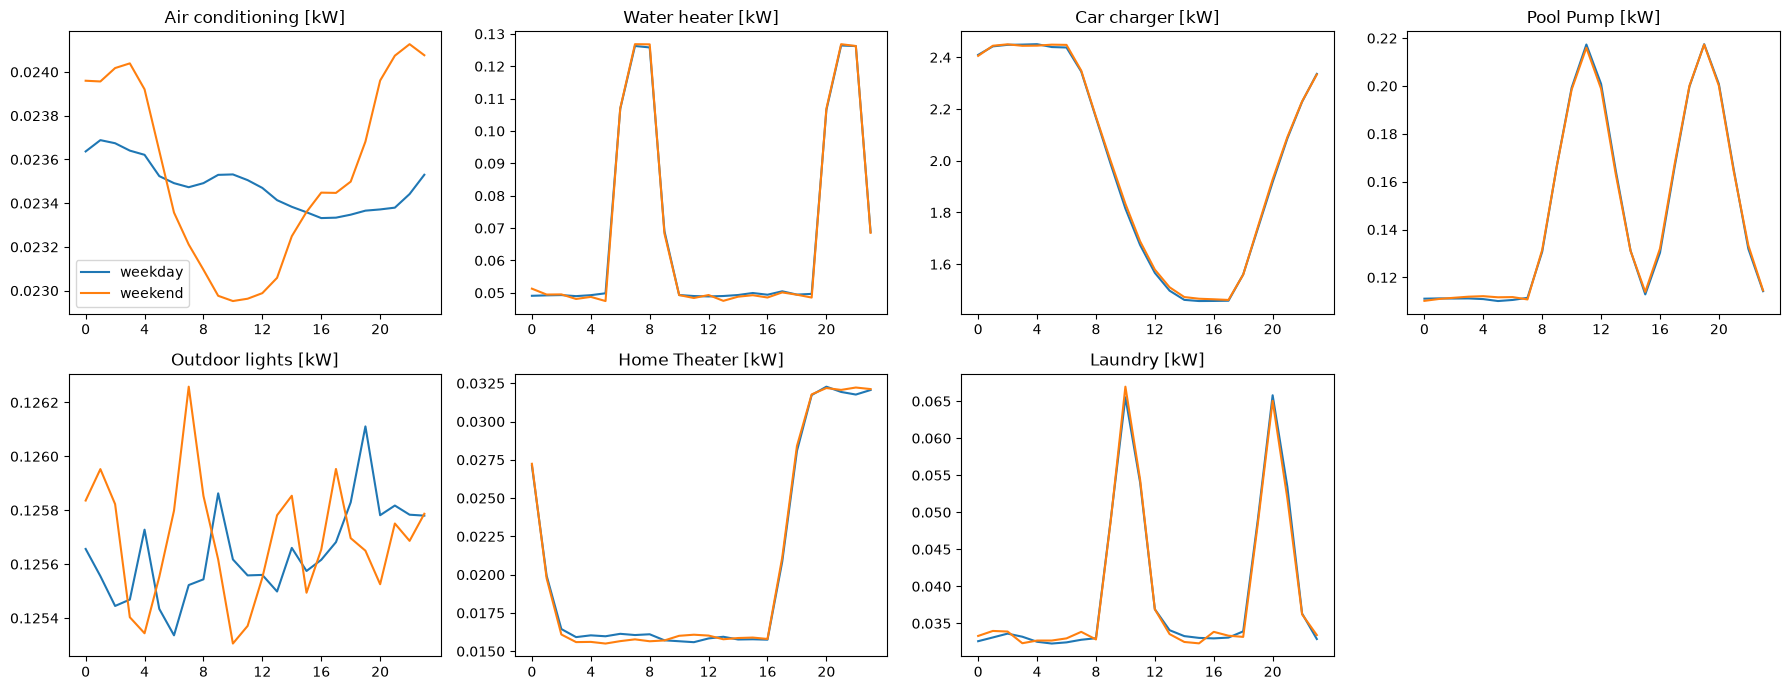

In [36]:
dev = df[BIG_DEVICES]

summary = dev.describe(percentiles=[.05, .25, .5, .75, .95]).T
summary["unique"] = dev.nunique()
print(summary.round(3))

prof24 = dev.groupby(df.index.hour).mean()
swing = (prof24.max() - prof24.min()) / prof24.mean() * 100
print("\nDaily swing (% of mean):")
print(swing.round(1))

fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, col in zip(axes.ravel(), BIG_DEVICES):
    for wk, label in [(0, "weekday"), (1, "weekend")]:
        sub = dev[df["is_weekend"] == wk]
        prof = sub[col].groupby(sub.index.hour).mean()
        ax.plot(prof.index, prof.values, label=label)
    ax.set_title(col)
    ax.set_xticks(range(0, 24, 4))
axes.ravel()[0].legend()
axes.ravel()[-1].axis("off")
fig.tight_layout()
fig.savefig(OUT / "device_daily_profiles.png", dpi=150)
plt.show()

## 🧩 Cell 4 · Cluster Daily Usage

- Shows each device's **correlation with temperature**
- Runs **KMeans** (k = 2 to 5) on each device's daily usage shapes
- Scores each k with **silhouette** and picks the best one
- Shows each cluster's weekend share and average temperature

In [37]:
print("corr with temperature (temperature  °F):")
print(df[BIG_DEVICES + ["use_HO"]].corrwith(df["temperature"]).round(2))

def daily_matrix(col):
    m = df[col].groupby([df.index.date, df.index.hour]).mean().unstack()
    m = m.dropna()
    m.index = pd.to_datetime(m.index)
    return m

def scaled(M):
    return (M - M.values.mean()) / M.values.std()

results = []
for col in HABIT_DEVICES:
    X = scaled(daily_matrix(col))
    for k in range(2, 6):
        km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
        results.append({"device": col, "k": k,
                        "silhouette": silhouette_score(X, km.labels_)})
res = pd.DataFrame(results)

print("\ndays per device:", len(daily_matrix(HABIT_DEVICES[0])))
print("\nSilhouette (rows = device, cols = k):")
print(res.pivot(index="device", columns="k", values="silhouette").round(3))

daily_temp = df["temperature"].resample("D").mean()
best = res.loc[res.groupby("device")["silhouette"].idxmax()]
for _, r in best.iterrows():
    M = daily_matrix(r["device"])
    cl = KMeans(n_clusters=int(r["k"]), n_init=10, random_state=42).fit_predict(scaled(M))
    info = pd.DataFrame({"cluster": cl,
                         "weekend": (M.index.day_of_week >= 5).astype(int),
                         "temp": daily_temp.reindex(M.index).values}, index=M.index)
    print(f"\n{r['device']}  (best k={int(r['k'])}, silhouette={r['silhouette']:.3f})")
    print(info.groupby("cluster").agg(days=("weekend", "size"),
                                      pct_weekend=("weekend", "mean"),
                                      mean_temp=("temp", "mean")).round(2))

corr with temperature (temperature  °F):
Air conditioning [kW]    0.99
Water heater [kW]       -0.00
Car charger [kW]         0.00
Pool Pump [kW]           0.04
Outdoor lights [kW]      0.00
Home Theater [kW]       -0.01
Laundry [kW]            -0.01
use_HO                   0.01
dtype: float64

days per device: 349

Silhouette (rows = device, cols = k):
k                      2      3      4      5
device                                       
Car charger [kW]   0.162  0.131  0.113  0.099
Home Theater [kW]  0.076  0.066  0.064  0.061
Laundry [kW]       0.061  0.056  0.056  0.051
Pool Pump [kW]     0.095  0.089  0.087  0.083
Water heater [kW]  0.051  0.047  0.045  0.042

Car charger [kW]  (best k=2, silhouette=0.162)
         days  pct_weekend  mean_temp
cluster                              
0         166         0.33      49.07
1         183         0.25      52.34

Home Theater [kW]  (best k=2, silhouette=0.076)
         days  pct_weekend  mean_temp
cluster                           

## 💡 Cell 5 · Scheduling Suggestions

Defines functions that find each device's **peak-usage windows** (every day, or weekday/weekend separately) and turn them into suggestions like:

> *"Water heater peaks from 18:00 to 22:00 every day. Create an automatic schedule?"*

Then runs them and prints the suggestions.

In [38]:
def high_windows(profile, frac=0.5):
    p = profile.reindex(range(24))
    on = (p >= p.min() + frac * (p.max() - p.min())).to_numpy()
    if on.all() or not on.any():
        return []
    wins = []
    for h in range(24):
        if on[h] and not on[h - 1]:
            end = h
            while on[(end + 1) % 24]:
                end += 1
            wins.append((h, (end + 1) % 24))
    return wins


def _fmt(h):
    return f"{h:02d}:00"


def _by_hour(s):
    return s.groupby(s.index.hour).mean().reindex(range(24))


def suggest_rules(df, devices=HABIT_DEVICES, frac=0.5, split_tol=0.2, verbose=False):
    out = []
    for dev in devices:
        name = dev.replace(" [kW]", "")
        p_all = _by_hour(df[dev])
        p_wd = _by_hour(df.loc[df["is_weekend"] == 0, dev])
        p_we = _by_hour(df.loc[df["is_weekend"] == 1, dev])


        gap = (p_wd - p_we).abs().max() / (p_all.max() - p_all.min())
        if verbose:
            print(f"{name:18s} weekday-vs-weekend gap = {gap:.2f}")

        if gap < split_tol:
            groups = [("every day", p_all)]
        else:
            groups = [("on weekdays", p_wd), ("on weekends", p_we)]

        for when, prof in groups:
            for s, e in high_windows(prof, frac):
                end = _fmt(e) + (" (next day)" if e <= s else "")
                out.append(f"{name} peaks from {_fmt(s)} to {end} {when}. "
                           f"Create an automatic schedule?")
    return out


for line in suggest_rules(df, verbose=True):
    print("-", line)

Water heater       weekday-vs-weekend gap = 0.03
Pool Pump          weekday-vs-weekend gap = 0.02
Laundry            weekday-vs-weekend gap = 0.05
Home Theater       weekday-vs-weekend gap = 0.03
Car charger        weekday-vs-weekend gap = 0.02
- Water heater peaks from 06:00 to 09:00 every day. Create an automatic schedule?
- Water heater peaks from 20:00 to 23:00 every day. Create an automatic schedule?
- Pool Pump peaks from 09:00 to 14:00 every day. Create an automatic schedule?
- Pool Pump peaks from 17:00 to 22:00 every day. Create an automatic schedule?
- Laundry peaks from 10:00 to 12:00 every day. Create an automatic schedule?
- Laundry peaks from 20:00 to 22:00 every day. Create an automatic schedule?
- Home Theater peaks from 18:00 to 01:00 (next day) every day. Create an automatic schedule?
- Car charger peaks from 21:00 to 10:00 (next day) every day. Create an automatic schedule?


## 🔍 Cell 6 · Check Peak Thresholds

Prints each device's **lowest** and **highest** hourly average, plus the **50% threshold** used to decide what counts as a "peak".

In [39]:
for dev in HABIT_DEVICES:
    prof = df[dev].groupby(df.index.hour).mean()
    print(f"{dev:22s} low={prof.min():.3f}  high={prof.max():.3f}  "
          f"threshold(50%)={prof.min() + 0.5*(prof.max()-prof.min()):.3f}")

Water heater [kW]      low=0.049  high=0.127  threshold(50%)=0.088
Pool Pump [kW]         low=0.111  high=0.217  threshold(50%)=0.164
Laundry [kW]           low=0.032  high=0.066  threshold(50%)=0.049
Home Theater [kW]      low=0.016  high=0.032  threshold(50%)=0.024
Car charger [kW]       low=1.460  high=2.449  threshold(50%)=1.954


## 🗂️ Cell 7 · Load & Clean UCI Data

Reads the household power file and converts it to hourly averages.

- Fills short gaps (≤ 3 hours), drops long gaps
- Computes `unmetered` consumption
- Adds time columns
- 💾 Saves `task3_uci_hourly.csv`

In [40]:
hourly = pd.read_csv(CLEAN_CSV, index_col=0, parse_dates=True)

SUBS = ["Sub_metering_1", "Sub_metering_2", "Sub_metering_3"]
needed = ["Global_active_power"] + SUBS + ["unmetered", "hour", "is_weekend"]
missing_cols = [c for c in needed if c not in hourly.columns]
assert not missing_cols, f"columns missing from clean_energy.csv: {missing_cols}"
assert hourly.isna().sum().sum() == 0
assert hourly.index.is_monotonic_increasing and not hourly.index.has_duplicates

step = hourly.index.to_series().diff().dt.total_seconds().div(3600)
print("clean:", hourly.shape, hourly.index.min(), "->", hourly.index.max())
print("nulls:", int(hourly.isna().sum().sum()),
      "| places where the index jumps more than 1 hour (gaps from Task 1):", int((step > 1).sum()))

clean: (34169, 12) 2006-12-16 17:00:00 -> 2010-11-26 21:00:00
nulls: 0 | places where the index jumps more than 1 hour (gaps from Task 1): 7


## 🧪 Cell 8 · Train/Test Split & Fault Injection

- Splits the data **70% train / 30% test**
- Injects artificial faults into the test set:
  - `spike`
  - `stuck_on`
  - `drop_to_zero`
- Stores fault locations in `labels` so we can measure model accuracy later

In [41]:
cut = int(len(hourly) * 0.70)
train = hourly.iloc[:cut].copy()
test_clean = hourly.iloc[cut:].copy()
print(f"train: {len(train)} rows  {train.index.min()} -> {train.index.max()}")
print(f"test : {len(test_clean)} rows  {test_clean.index.min()} -> {test_clean.index.max()}")

rng = np.random.default_rng(42)
test = test_clean.copy()
j = {c: test.columns.get_loc(c) for c in test.columns}

labels = np.zeros(len(test), dtype=int)
kinds = np.array([""] * len(test), dtype=object)
events = []

BLOCK = 48
plan = ["spike"] * 20 + ["stuck_on"] * 10 + ["drop_to_zero"] * 10
blocks = rng.choice(len(test) // BLOCK, size=len(plan), replace=False)
stuck_level = train["Sub_metering_3"].quantile(0.99)
hours = test["hour"].to_numpy()

for kind, b in zip(plan, blocks):
    base = int(b) * BLOCK
    if kind == "spike":
        start = end = base + int(rng.integers(0, 40))
        test.iloc[start, j["Global_active_power"]] += 4.0      # a device suddenly draws 4 kW extra
    elif kind == "stuck_on":
        start = base + int(rng.integers(0, 30)); end = start + 11
        sl = slice(start, end + 1)
        s3 = test.iloc[sl, j["Sub_metering_3"]].to_numpy()
        delta = np.clip(stuck_level - s3, 0, None)
        test.iloc[sl, j["Sub_metering_3"]] = s3 + delta
        test.iloc[sl, j["Global_active_power"]] = test.iloc[sl, j["Global_active_power"]].to_numpy() + delta * 0.06
    else:
        start = base + int(np.argmax(hours[base:base + BLOCK] == 18)); end = start + 3
        assert hours[start] == 18, "no 18:00 inside the block"
        for c in ["Global_active_power"] + SUBS:
            test.iloc[start:end + 1, j[c]] = 0.0
    labels[start:end + 1] = 1
    kinds[start:end + 1] = kind
    events.append({"kind": kind, "start": start, "end": end})

test["unmetered"] = test["Global_active_power"] * 1000 / 60 - test[SUBS].sum(axis=1)

print("\ninjected hours:", int(labels.sum()), f"({labels.mean() * 100:.2f}% of test)")
print(pd.Series(kinds[labels == 1]).value_counts())
print("stuck_on level (Wh/min):", round(float(stuck_level), 2))

full = pd.concat([train, test])

idx = test.index
span_bad = [e for e in events
            if idx[e["end"]] - idx[e["start"]] != pd.Timedelta(hours=e["end"] - e["start"])]
print("events spanning a data gap:", len(span_bad), "of", len(events))

train: 23918 rows  2006-12-16 17:00:00 -> 2009-09-13 15:00:00
test : 10251 rows  2009-09-13 16:00:00 -> 2010-11-26 21:00:00

injected hours: 180 (1.76% of test)
stuck_on        120
drop_to_zero     40
spike            20
Name: count, dtype: int64
stuck_on level (Wh/min): 19.23
events spanning a data gap: 0 of 40


## 🌲 Cell 9 · First Isolation Forest Test

- `evaluate()` → precision, recall, false-alarm rate, and faults caught per type
- `sweep()` → tries several `contamination` values
- Runs both using the **basic features**

In [42]:
FEATS = ["Global_active_power", "Sub_metering_1", "Sub_metering_2",
         "Sub_metering_3", "unmetered", "hour"]


def evaluate(pred):
    tp = int(((pred == 1) & (labels == 1)).sum())
    fp = int(((pred == 1) & (labels == 0)).sum())
    fn = int(((pred == 0) & (labels == 1)).sum())
    row = {
        "precision": tp / max(tp + fp, 1),
        "recall_hours": tp / max(tp + fn, 1),
        "false_alarm_rate": fp / int((labels == 0).sum()),
    }
    for kind in ["spike", "stuck_on", "drop_to_zero"]:
        ev = [e for e in events if e["kind"] == kind]
        caught = sum(bool(pred[e["start"]:e["end"] + 1].any()) for e in ev)
        row[f"{kind}_caught"] = f"{caught}/{len(ev)}"
    return row


def sweep(X_tr, X_te, contaminations=(0.005, 0.01, 0.02, 0.05)):
    rows = []
    for c in contaminations:
        iso = IsolationForest(n_estimators=300, contamination=c,
                              random_state=42, n_jobs=-1).fit(X_tr)
        p = (iso.predict(X_te) == -1).astype(int)
        rows.append({"contamination": c, **evaluate(p)})
    return pd.DataFrame(rows).round(3)


X_train = train[FEATS]
X_test = test[FEATS]
print(sweep(X_train, X_test).to_string(index=False))

 contamination  precision  recall_hours  false_alarm_rate spike_caught stuck_on_caught drop_to_zero_caught
         0.005      0.091         0.011             0.002         2/20            0/10                0/10
         0.010      0.089         0.028             0.005         5/20            0/10                0/10
         0.020      0.165         0.117             0.011        20/20            1/10                0/10
         0.050      0.068         0.133             0.033        20/20            3/10                0/10


## 🛠️ Cell 10 · Improved Features (v2)

Adds features that compare each value to the **typical value for that hour** (z-scores), plus rolling min/max over recent hours. Re-runs the sweep.

In [43]:
BASE = ["Global_active_power", "Sub_metering_1", "Sub_metering_2",
        "Sub_metering_3", "unmetered"]

mu_h = train.groupby("hour")[BASE].mean()
sd_h = train.groupby("hour")[BASE].std().clip(lower=1e-3)

def build_features(d):
    f = pd.DataFrame(index=d.index)
    for c in BASE:
        f[c] = d[c]
        f[c + "_z"] = (d[c] - d["hour"].map(mu_h[c])) / d["hour"].map(sd_h[c])
    f["SM3_min6"] = d["Sub_metering_3"].rolling(6).min()
    f["GAP_max3"] = d["Global_active_power"].rolling(3).max()
    return f


F2 = build_features(full)
X_train2 = F2.loc[train.index].dropna()
X_test2 = F2.loc[test.index]
assert X_test2.notna().all().all()
print("features:", list(F2.columns))
print(sweep(X_train2, X_test2).to_string(index=False))

features: ['Global_active_power', 'Global_active_power_z', 'Sub_metering_1', 'Sub_metering_1_z', 'Sub_metering_2', 'Sub_metering_2_z', 'Sub_metering_3', 'Sub_metering_3_z', 'unmetered', 'unmetered_z', 'SM3_min6', 'GAP_max3']
 contamination  precision  recall_hours  false_alarm_rate spike_caught stuck_on_caught drop_to_zero_caught
         0.005      0.231         0.033             0.002         5/20            1/10                0/10
         0.010      0.172         0.061             0.005         8/20            2/10                0/10
         0.020      0.164         0.122             0.011        18/20            3/10                0/10
         0.050      0.098         0.206             0.034        20/20            5/10                0/10


## ⏱️ Cell 11 · Time-Context Features (v3)

Computes the **expected value** for each hour from the previous 7 days, then builds features comparing the current value to that expectation and to the preceding hours. Re-runs the sweep.

In [44]:
grid = pd.date_range(full.index.min(), full.index.max(), freq="1h")
fg = full.reindex(grid)


def expected_same_hour(s, days=7, min_days=4):
    lags = pd.concat([s.shift(24 * k) for k in range(1, days + 1)], axis=1)
    return lags.mean(axis=1).where(lags.notna().sum(axis=1) >= min_days)


gap = fg["Global_active_power"]
sm3 = fg["Sub_metering_3"]
exp_gap = expected_same_hour(gap)

F3 = pd.DataFrame(index=grid)
F3["GAP"] = gap
F3["GAP_ratio"] = gap / (exp_gap + 0.1)
F3["GAP_diff"] = gap - exp_gap
F3["GAP_ratio_prev3"] = gap / (gap.shift(1).rolling(3).mean() + 0.1)
F3["SM3"] = sm3
F3["SM3_min6"] = sm3.rolling(6).min()
F3["SM3_std6"] = sm3.rolling(6).std()
F3["hour"] = grid.hour

X_train3 = F3.loc[train.index].dropna()
X_test3 = F3.loc[test.index]
n_filled = int(X_test3.isna().any(axis=1).sum())
X_test3 = X_test3.fillna(X_train3.median())
print("features:", list(F3.columns))
print(f"train rows: {len(X_train3)} | test rows with missing context (filled): {n_filled}")
print(sweep(X_train3, X_test3).to_string(index=False))

features: ['GAP', 'GAP_ratio', 'GAP_diff', 'GAP_ratio_prev3', 'SM3', 'SM3_min6', 'SM3_std6', 'hour']
train rows: 23807 | test rows with missing context (filled): 171
 contamination  precision  recall_hours  false_alarm_rate spike_caught stuck_on_caught drop_to_zero_caught
         0.005      0.360         0.100             0.003        17/20            1/10                0/10
         0.010      0.259         0.167             0.009        19/20            5/10                0/10
         0.020      0.183         0.222             0.018        19/20            5/10                0/10
         0.050      0.143         0.483             0.052        20/20           10/10                0/10


## 🩺 Cell 12 · Diagnose the Model

Compares the anomaly scores for each fault type against the detection **threshold**, and shows an example `drop_to_zero` event to understand why some faults get missed.

In [45]:
iso = IsolationForest(n_estimators=300, contamination=0.05,
                      random_state=42, n_jobs=-1).fit(X_train3)
s_test = pd.Series(iso.score_samples(X_test3), index=X_test3.index)
thr = iso.offset_

for kind in ["spike", "stuck_on", "drop_to_zero"]:
    sc = s_test.iloc[np.where(kinds == kind)[0]]
    print(f"{kind:13s} median score = {sc.median():.3f} | share below threshold = {(sc < thr).mean():.2f}")
print(f"threshold = {thr:.3f} | normal test hours below it: {(s_test[labels == 0] < thr).mean():.3f}")

e = [e for e in events if e["kind"] == "drop_to_zero"][0]
print(test.iloc[e["start"]:e["end"] + 1][["Global_active_power", "Sub_metering_3", "hour"]])

spike         median score = -0.710 | share below threshold = 1.00
stuck_on      median score = -0.572 | share below threshold = 0.56
drop_to_zero  median score = -0.503 | share below threshold = 0.00
threshold = -0.569 | normal test hours below it: 0.052
                     Global_active_power  Sub_metering_3  hour
datetime                                                      
2010-07-22 18:00:00                  0.0             0.0    18
2010-07-22 19:00:00                  0.0             0.0    19
2010-07-22 20:00:00                  0.0             0.0    20
2010-07-22 21:00:00                  0.0             0.0    21


## 🏁 Cell 13 · Final Model

- Trains the final model (`contamination = 0.01`)
- Evaluates it on the test set
- 💾 Saves `anomaly_model.joblib` (model + feature list + fill values)

In [51]:
FEATURES = list(F3.columns)

# Rule thresholds come from the normal training data only
RULE_Q = 0.001
rule_thr = {
    "GAP_ratio_low":   X_train3["GAP_ratio"].quantile(RULE_Q),
    "GAP_diff_high":   X_train3["GAP_diff"].quantile(1 - RULE_Q),
    "SM3_min6_high":   X_train3["SM3_min6"].quantile(1 - RULE_Q),
}
print({k: round(float(v), 3) for k, v in rule_thr.items()})


def apply_rules(X, thr=rule_thr):
    return pd.DataFrame({
        "low_power":  X["GAP_ratio"] < thr["GAP_ratio_low"],     # consumption collapses vs usual
        "power_jump": X["GAP_diff"] > thr["GAP_diff_high"],      # far above the usual for this hour
        "stuck_high": X["SM3_min6"] > thr["SM3_min6_high"],      # device never drops for 6 hours
    }, index=X.index)


iso_final = IsolationForest(n_estimators=300, contamination=0.01,
                            random_state=42, n_jobs=-1).fit(X_train3)
iso_flag = (iso_final.predict(X_test3) == -1)
rules = apply_rules(X_test3)

print("\nIsolation Forest alone:")
print(pd.Series(evaluate(iso_flag.astype(int))).to_string())
for name in rules:
    print(f"\nrule {name} alone:")
    print(pd.Series(evaluate(rules[name].to_numpy().astype(int))).to_string())

pred_final = (iso_flag | rules.any(axis=1).to_numpy()).astype(int)
print("\nIsolation Forest + rules:")
print(pd.Series(evaluate(pred_final)).to_string())

bundle = {"model": iso_final, "features": FEATURES, "rule_thresholds": {k: float(v) for k, v in rule_thr.items()},
          "fill_values": X_train3.median().to_dict(), "contamination": 0.01,
          "sklearn_version": sklearn.__version__}
joblib.dump(bundle, OUT / "anomaly_model.joblib")
print("saved:", OUT / "anomaly_model.joblib")
print(pd.Series(evaluate(pred_final)).to_string())

{'GAP_ratio_low': 0.102, 'GAP_diff_high': 3.756, 'SM3_min6_high': 18.267}

Isolation Forest alone:
precision              0.258621
recall_hours           0.166667
false_alarm_rate       0.008539
spike_caught              19/20
stuck_on_caught            5/10
drop_to_zero_caught        0/10

rule low_power alone:
precision                   1.0
recall_hours           0.222222
false_alarm_rate            0.0
spike_caught               0/20
stuck_on_caught            0/10
drop_to_zero_caught       10/10

rule power_jump alone:
precision              0.933333
recall_hours           0.077778
false_alarm_rate       0.000099
spike_caught              14/20
stuck_on_caught            0/10
drop_to_zero_caught        0/10

rule stuck_high alone:
precision              0.222222
recall_hours                0.4
false_alarm_rate       0.025022
spike_caught               0/20
stuck_on_caught           10/10
drop_to_zero_caught        0/10

Isolation Forest + rules:
precision              0.295045
rec

## 📈 Cell 14 · Plot Detected Faults

Picks the **28-day window** with the most faults and plots consumption with:

- 🟠 Orange circles → injected faults
- 🔴 Red dots → faults flagged by the model

💾 Saves `anomaly_timeline.png`

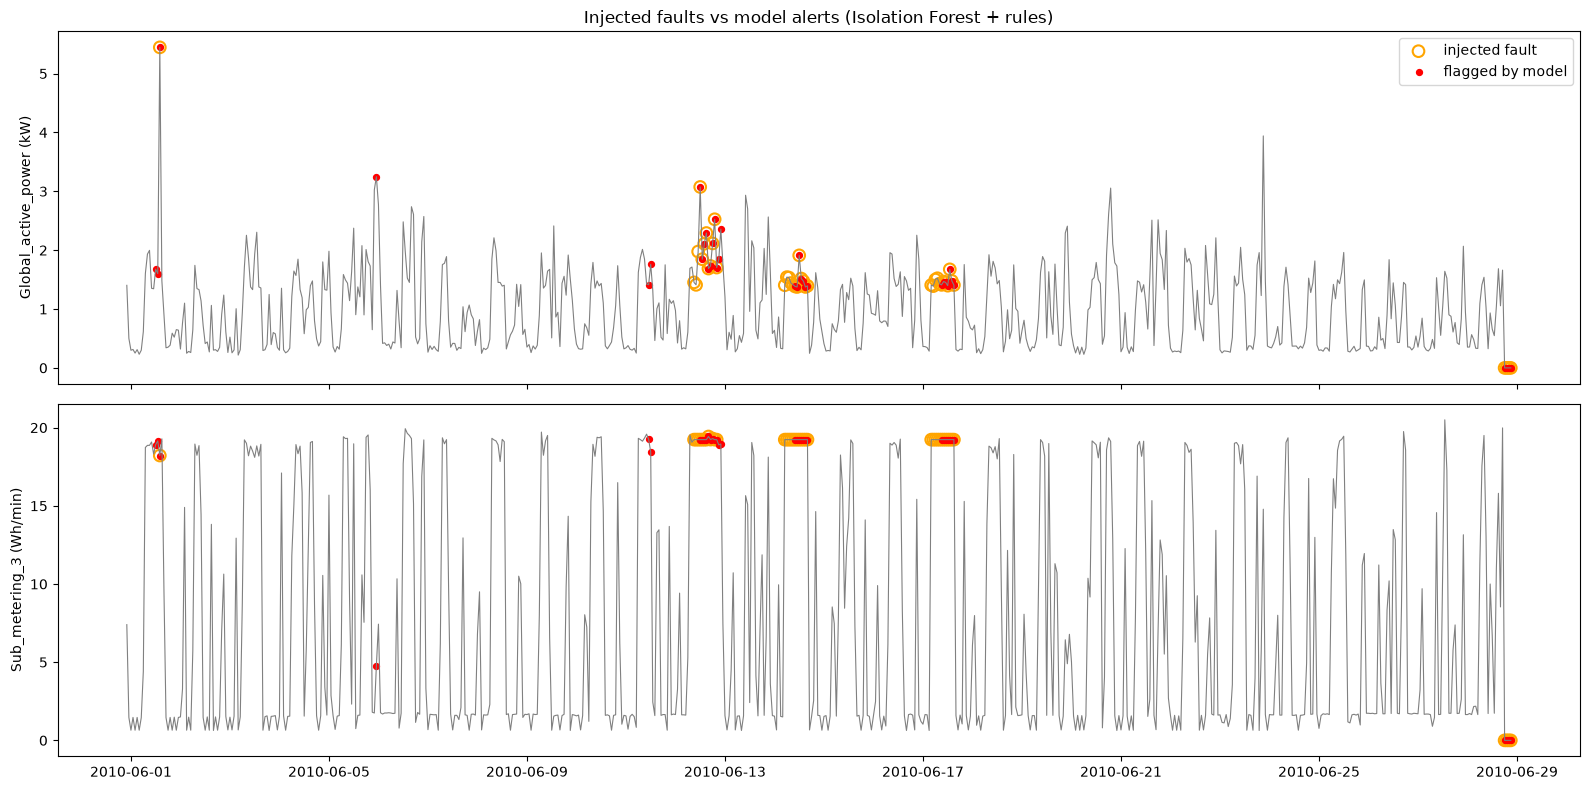

In [52]:
flag = pd.Series(pred_final, index=test.index)
truth = pd.Series(labels, index=test.index)

w = 24 * 28
end = truth.rolling(w).sum().idxmax()
win = test.loc[end - pd.Timedelta(hours=w - 1): end]
inj = win[truth.loc[win.index] == 1]
fl = win[flag.loc[win.index] == 1]

fig, (ax, ax2) = plt.subplots(2, 1, figsize=(16, 8), sharex=True)

ax.plot(win.index, win["Global_active_power"], color="gray", lw=0.8)
ax.scatter(inj.index, inj["Global_active_power"], s=70, facecolors="none",
           edgecolors="orange", linewidths=1.5, label="injected fault")
ax.scatter(fl.index, fl["Global_active_power"], s=18, color="red", label="flagged by model")
ax.set_ylabel("Global_active_power (kW)")
ax.set_title("Injected faults vs model alerts (Isolation Forest + rules)")
ax.legend()

ax2.plot(win.index, win["Sub_metering_3"], color="gray", lw=0.8)
ax2.scatter(inj.index, inj["Sub_metering_3"], s=70, facecolors="none",
            edgecolors="orange", linewidths=1.5)
ax2.scatter(fl.index, fl["Sub_metering_3"], s=18, color="red")
ax2.set_ylabel("Sub_metering_3 (Wh/min)")

fig.tight_layout()
fig.savefig(OUT / "anomaly_timeline.png", dpi=150)
plt.show()

## 📝 Cell 15 · Write `anomaly_habits.py`

Writes a standalone Python module with the final code:

- `detect()` → finds faults using the saved model
- `suggest_rules()` → generates habit-based schedule suggestions
- Can also be run from the command line

In [48]:
ANOMALY_HABITS_PY = r'''from pathlib import Path

import joblib
import pandas as pd

MODEL_PATH = Path(__file__).with_name("anomaly_model.joblib")

HABIT_DEVICES = ["Water heater [kW]", "Pool Pump [kW]", "Laundry [kW]",
                 "Home Theater [kW]", "Car charger [kW]"]


# ---------------- fault detection ----------------
def _expected_same_hour(s, days=7, min_days=4):
    lags = pd.concat([s.shift(24 * k) for k in range(1, days + 1)], axis=1)
    return lags.mean(axis=1).where(lags.notna().sum(axis=1) >= min_days)


def apply_rules(X, thr):
    return pd.DataFrame({
        "low_power":  X["GAP_ratio"] < thr["GAP_ratio_low"],    # consumption collapses vs usual
        "power_jump": X["GAP_diff"] > thr["GAP_diff_high"],     # far above the usual for this hour
        "stuck_high": X["SM3_min6"] > thr["SM3_min6_high"],     # device never drops for 6 hours
    }, index=X.index)


def detect(df, model_path=MODEL_PATH):
    """Isolation Forest + three simple rules. Returns one row per hour with data."""
    bundle = joblib.load(model_path)
    if "rule_thresholds" not in bundle:
        raise ValueError("anomaly_model.joblib has no rule_thresholds: re-run cell 13 of the notebook")
    d = df.sort_index()
    grid = pd.date_range(d.index.min(), d.index.max(), freq="1h")
    d = d.reindex(grid)
    gap = d["Global_active_power"].astype(float)
    sm3 = d["Sub_metering_3"].astype(float)
    exp_gap = _expected_same_hour(gap)

    F = pd.DataFrame(index=grid)
    F["GAP"] = gap
    F["GAP_ratio"] = gap / (exp_gap + 0.1)
    F["GAP_diff"] = gap - exp_gap
    F["GAP_ratio_prev3"] = gap / (gap.shift(1).rolling(3).mean() + 0.1)
    F["SM3"] = sm3
    F["SM3_min6"] = sm3.rolling(6).min()
    F["SM3_std6"] = sm3.rolling(6).std()
    F["hour"] = grid.hour
    F = F[bundle["features"]]

    valid = gap.notna() & sm3.notna()
    has_context = F.notna().all(axis=1)
    X = F.fillna(pd.Series(bundle["fill_values"]))[valid]

    iso_flag = bundle["model"].predict(X) == -1
    rules = apply_rules(X, bundle["rule_thresholds"])
    out = pd.DataFrame({
        "anomaly": iso_flag | rules.any(axis=1).to_numpy(),
        "score": bundle["model"].score_samples(X),
        "iso": iso_flag,
        "has_context": has_context[valid],
    }, index=X.index)
    return out.join(rules)


# ---------------- habit suggestions ----------------
def high_windows(profile, frac=0.5):
    p = profile.reindex(range(24))
    on = (p >= p.min() + frac * (p.max() - p.min())).to_numpy()
    if on.all() or not on.any():
        return []
    wins = []
    for h in range(24):
        if on[h] and not on[h - 1]:
            end = h
            while on[(end + 1) % 24]:
                end += 1
            wins.append((h, (end + 1) % 24))
    return wins


def _fmt(h):
    return f"{h:02d}:00"


def _by_hour(s):
    return s.groupby(s.index.hour).mean().reindex(range(24))


def suggest_rules(df, devices=HABIT_DEVICES, frac=0.5, split_tol=0.2, verbose=False):
    if "is_weekend" not in df.columns:
        df = df.assign(is_weekend=(df.index.day_of_week >= 5).astype(int))
    out = []
    for dev in devices:
        name = dev.replace(" [kW]", "")
        p_all = _by_hour(df[dev])
        p_wd = _by_hour(df.loc[df["is_weekend"] == 0, dev])
        p_we = _by_hour(df.loc[df["is_weekend"] == 1, dev])

        gap = (p_wd - p_we).abs().max() / (p_all.max() - p_all.min())
        if verbose:
            print(f"{name:18s} weekday-vs-weekend gap = {gap:.2f}")

        if gap < split_tol:
            groups = [("every day", p_all)]
        else:
            groups = [("on weekdays", p_wd), ("on weekends", p_we)]

        for when, prof in groups:
            for s, e in high_windows(prof, frac):
                end = _fmt(e) + (" (next day)" if e <= s else "")
                out.append(f"{name} peaks from {_fmt(s)} to {end} {when}. "
                           f"Create an automatic schedule?")
    return out


if __name__ == "__main__":
    import sys
    if len(sys.argv) != 3 or sys.argv[1] not in ("detect", "habits"):
        sys.exit("Usage: python anomaly_habits.py detect|habits hourly.csv")
    d = pd.read_csv(sys.argv[2], index_col=0, parse_dates=True)
    if sys.argv[1] == "detect":
        r = detect(d)
        print("flagged hours:", int(r["anomaly"].sum()), "of", len(r))
        print(r[r["anomaly"]].tail(10).round(3).to_string())
    else:
        print("\n".join(suggest_rules(d)))
'''
(OUT / "anomaly_habits.py").write_text(ANOMALY_HABITS_PY, encoding="utf-8")
print("saved:", OUT / "anomaly_habits.py")

saved: d:\Hass\energy\anomaly_habits.py


## ✅ Cell 16 · Verify & Save

- Imports the new module and checks its results **match the notebook**
- Trains a 2-cluster KMeans model for each habit device
- 💾 Saves them as `habit_kmeans.joblib`

In [49]:
import sys, importlib

sys.path.insert(0, str(OUT))
import anomaly_habits
importlib.reload(anomaly_habits)

det = anomaly_habits.detect(full)
mine = det.loc[test.index, "anomaly"].astype(int).to_numpy()
print("detect() == notebook:", bool((mine == pred_final).all()),
      "| flagged:", int(mine.sum()), "vs", int(pred_final.sum()))

print("suggest_rules() == notebook:", anomaly_habits.suggest_rules(df) == suggest_rules(df))
print("suggest_rules() without is_weekend:",
      anomaly_habits.suggest_rules(df.drop(columns=["is_weekend"])) == suggest_rules(df))

habit_models = {}
for dev in HABIT_DEVICES:
    M = daily_matrix(dev)
    mean, std = float(M.values.mean()), float(M.values.std())
    X = (M - mean) / std
    km = KMeans(n_clusters=2, n_init=10, random_state=42).fit(X)
    habit_models[dev] = {"model": km, "scale": (mean, std),
                         "silhouette": float(silhouette_score(X, km.labels_))}
    print(f"{dev:20s} silhouette={habit_models[dev]['silhouette']:.3f}")
joblib.dump(habit_models, OUT / "habit_kmeans.joblib")

detect() == notebook: True | flagged: 444 vs 444
suggest_rules() == notebook: True
suggest_rules() without is_weekend: True
Water heater [kW]    silhouette=0.051
Pool Pump [kW]       silhouette=0.095
Laundry [kW]         silhouette=0.061
Home Theater [kW]    silhouette=0.076
Car charger [kW]     silhouette=0.162


['d:\\Hass\\energy\\habit_kmeans.joblib']